# Chapter 4: Stochastic programming with spot-market recourse

## Setup

In [1]:
import os
import time
from itertools import product

import gurobipy as gp
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from gurobipy import GRB
from scipy.optimize import fsolve
from scipy.stats import norm

env = gp.Env(empty=True)
env.setParam("OutputFlag", 0)
env.start()

os.makedirs("results", exist_ok=True)
plt.rcParams.update({"font.size": 9, "lines.linewidth": 1.2, "pdf.fonttype": 42})

k, s, r = 15, 45, 10
GROUPS = [[0, 1, 2], [3, 4, 5], [6, 7, 8, 9]]
Q_COLS = [f"Q{i}" for i in range(1, 11)]

p_bench = np.array([0.05, 0.25, 0.15, 0.10, 0.20, 0.08, 0.12, 0.04, 0.17, 0.22])
y_bench = np.array([0.80, 0.40, 0.50, 0.70, 0.40, 0.60, 0.75, 0.90, 0.65, 0.85])
c_bench = np.array([40, 25, 35, 30, 21, 55, 45, 37, 52, 42], dtype=float)

In [2]:
# instance l* = 3, generated as in Introduction_data_latex.py (lines 30-40)
np.random.seed(3003)
p = np.random.uniform(np.maximum(0.02, p_bench - 0.05), np.minimum(0.35, p_bench + 0.05))
y = np.random.uniform(np.maximum(0.30, y_bench - 0.15), np.minimum(0.95, y_bench + 0.15))
c = np.random.uniform(np.maximum(r + 1, 0.90 * c_bench), np.minimum(s + k - 1, 1.10 * c_bench))
mu = np.random.uniform(350, 450)
sigma = np.random.uniform(0.20, 0.29) * mu
inst = {"p": p, "y": y, "c": c, "mu": mu, "sigma": sigma}

print(f"mu = {mu:.2f}, sigma = {sigma:.2f}")
pd.DataFrame({"supplier": range(1, 11), "p": p, "y": y, "c": c}).round(3)

mu = 353.12, sigma = 76.03


,supplier,p,y,c
0,1,0.047,0.713,38.558
1,2,0.271,0.364,24.806
2,3,0.111,0.575,34.965
3,4,0.067,0.721,31.365
4,5,0.204,0.426,20.145
5,6,0.105,0.671,50.144
6,7,0.110,0.666,47.579
7,8,0.045,0.869,39.397
8,9,0.161,0.708,51.580
9,10,0.186,0.912,43.592


## Functions

In [3]:
def generate(N, seed, inst, E_fixed=None):
    rng = np.random.default_rng(seed)
    n = len(inst["p"])
    # group events and number of hit groups
    E = (rng.random((N, 3)) < 0.15).astype(int)
    if E_fixed is not None:
        E = np.tile(np.asarray(E_fixed, dtype=int), (N, 1))
    H = E.sum(axis=1)
    # disruption probabilities and yield factors
    p_mod = np.tile(inst["p"], (N, 1))
    for g, members in enumerate(GROUPS):
        hit = E[:, g] == 1
        p_mod[np.ix_(hit, members)] = np.minimum(0.90, inst["p"][members] + 0.25)
    R = np.where(rng.random((N, n)) < p_mod, inst["y"], 1.0)
    # stressed demand and spot price
    D = np.maximum(0.0, (1 + 0.1 * H) * rng.normal(inst["mu"], inst["sigma"], N))
    SP = 30 + 15 * H + 30 * rng.random(N)
    return H, R, D, SP

In [4]:
def profit(Q, R, D, SP, inst):
    X = R @ Q
    shortage = np.maximum(0.0, D - X)
    # each unit short is bought on the spot market or lost, whichever is cheaper
    return (s - r) * D + r * X - R @ (inst["c"] * Q) - np.minimum(s - r + k, SP - r) * shortage


def active(Q):
    return " ".join(str(i + 1) for i in np.flatnonzero(Q > 1e-6))

In [5]:
def solve_saa(R, D, SP, inst, Q_fixed=None):
    N, n = R.shape
    with gp.Model(env=env) as m:
        # first stage: order quantities
        Q = m.addMVar(n, lb=0.0)
        if Q_fixed is not None:
            Q.lb = Q_fixed
            Q.ub = Q_fixed
        # second stage: sales, leftover, spot purchase, lost sales
        z = m.addMVar(N, lb=0.0)
        v = m.addMVar(N, lb=0.0)
        B = m.addMVar(N, lb=0.0)
        L = m.addMVar(N, lb=0.0)
        # supply + spot = sales + leftover; sales + lost sales = demand
        m.addConstr(z + v - R @ Q - B == 0)
        m.addConstr(z + L == D)
        # average profit over the scenarios
        m.setObjective((s * z.sum() + r * v.sum() - SP @ B - k * L.sum()) / N
                       - (inst["c"] * R.mean(axis=0)) @ Q, GRB.MAXIMIZE)
        m.optimize()
        return Q.X.copy(), m.ObjVal, m.Runtime

In [6]:
def saa_batches(N, seeds, val, inst, E_fixed=None):
    rows, solve_time, eval_time = [], 0.0, 0.0
    for m, seed in enumerate(seeds, start=1):
        # solve one SAA batch
        _, R, D, SP = generate(N, seed, inst, E_fixed)
        Q_hat, v_hat, t = solve_saa(R, D, SP, inst)
        solve_time += t
        # evaluate the candidate on the validation sample
        t0 = time.perf_counter()
        Pi = profit(Q_hat, *val, inst)
        eval_time += time.perf_counter() - t0
        rows.append({"m": m, "seed": seed, **dict(zip(Q_COLS, Q_hat)),
                     "v_hat": v_hat, "g_hat": Pi.mean(), "sd_Pi": Pi.std(ddof=1)})
    return pd.DataFrame(rows), solve_time, eval_time

In [7]:
# team's algorithm from Algorithm DMU Assignment.py (lines 14-121), mathematics unchanged
def preference_order(p, y, c, mu, sigma):
    N = len(p)
    CR = (s + k - c) / (s + k - r)

    # all 2^N disruption scenarios and their probabilities
    b_u = np.array(list(product([0, 1], repeat=N)))
    P_u = np.prod(b_u * p + (1 - b_u) * (1 - p), axis=1)

    # suppliers in increasing order of unit cost
    order = np.argsort(c)
    CR_ordered, y_ordered, p_ordered = CR[order], y[order], p[order]
    b_ordered = b_u[:, order]
    normal = norm(mu, sigma)

    def optimalcond(Q, active):
        i = len(active)
        onesi = np.ones(i)
        ones_matr = np.ones((i, np.size(b_ordered, 0)))
        LHS = np.diag(CR_ordered[0:i]) @ (onesi - (np.diag(onesi - y_ordered[0:i])) @ p_ordered[0:i])
        Q_u = Q @ (ones_matr - (np.diag(onesi - y_ordered[0:i]) @ np.transpose(b_ordered[:, 0:i])))
        FQ_u = normal.cdf(Q_u)
        return (LHS - (ones_matr - (np.diag(onesi - y_ordered[0:i]) @ np.transpose(b_ordered[:, 0:i])))
                @ np.diag(FQ_u) @ P_u).flatten()

    def acceptor(Q, active, bound=0.01):
        resid = optimalcond(Q, active)
        accept_resid = np.all(np.abs(resid) <= bound)
        nonneg = Q >= 0
        return accept_resid, np.all(nonneg), nonneg

    def kkt_inactivity(root, active, order):
        i = len(order)
        j = len(active)
        onesi = np.ones(i)
        onesj = np.ones(j)
        ones_matrj = np.ones((j, np.size(b_ordered, 0)))
        ones_matri = np.ones((i, np.size(b_ordered, 0)))
        LHS = np.diag(CR_ordered[N - i:]) @ (onesi - (np.diag(onesi - y_ordered[N - i:])) @ p_ordered[N - i:])
        Q_u = root @ (ones_matrj - (np.diag(onesj - y_ordered[0:j]) @ np.transpose(b_ordered[:, 0:j])))
        FQ_u = normal.cdf(Q_u)
        return LHS - (ones_matri - (np.diag(onesi - y_ordered[N - i:]) @ np.transpose(b_ordered[:, N - i:]))) \
            @ np.diag(FQ_u) @ P_u

    order = list(order)
    active = []
    while order:
        # add the next-cheapest supplier and solve the first-order conditions
        active.append(order.pop(0))
        guess = (440 / len(active)) * np.ones(len(active))
        root = fsolve(optimalcond, x0=guess, args=(active,), xtol=1e-4)
        accept_resid, accept_nonneg, nonneg = acceptor(root, active)
        if accept_resid and accept_nonneg:
            # KKT check: remaining suppliers from the first one with LHS <= RHS stay inactive
            diff = kkt_inactivity(root, active, order)
            for j in range(len(diff)):
                if diff[j] <= 0:
                    order = order[:j]
                    break
        elif not accept_nonneg:
            # drop suppliers with a negative quantity
            active = list(np.array(active)[nonneg])
            continue
        else:
            raise RuntimeError("residuals imply the solution does not solve the optimality conditions")

    Q = np.zeros(N)
    Q[active] = root
    return Q

## 4.3 SAA analysis

In [8]:
SETTINGS = [(50, 5), (1000, 5), (2000, 5)]
N_VAL, VAL_SEED = 10_000, 4999
val = generate(N_VAL, VAL_SEED, inst)[1:]

candidates, saa = [], []
for idx, (N, M) in enumerate(SETTINGS, start=1):
    start = time.perf_counter()
    cand, solve_time, eval_time = saa_batches(N, [4000 + 100 * idx + m for m in range(1, M + 1)], val, inst)
    # upper bound on v*
    U = cand["v_hat"].mean() + 2.776 * cand["v_hat"].std(ddof=1) / np.sqrt(M)
    # select best candidate on validation sample
    best = cand.loc[cand["g_hat"].idxmax()]
    # lower bound from the profits of the selected candidate
    L = best["g_hat"] - 1.96 * best["sd_Pi"] / np.sqrt(N_VAL)
    cand.insert(0, "N", N)
    candidates.append(cand)
    saa.append({"N": N, "M": M, "chosen_m": int(best["m"]), **best[Q_COLS], "g_hat": best["g_hat"],
                "U": U, "L": L, "gap": U - L, "solve_time_s": solve_time, "eval_time_s": eval_time,
                "total_time_s": time.perf_counter() - start})
candidates = pd.concat(candidates, ignore_index=True)
saa = pd.DataFrame(saa)
candidates.round(2)

,N,m,seed,Q1,Q2,Q3,Q4,Q5,Q6,Q7,Q8,Q9,Q10,v_hat,g_hat,sd_Pi
0,50,1,4101,0.0,81.86,0.0,0.0,400.73,0.0,0.0,0.0,0.0,0.0,7154.29,6856.10,2685.66
1,50,2,4102,0.0,0.00,0.0,0.0,456.41,0.0,0.0,0.0,0.0,0.0,6527.22,6926.97,2988.12
2,50,3,4103,0.0,0.00,0.0,0.0,491.82,0.0,0.0,0.0,0.0,0.0,7029.73,6880.79,2941.33
3,50,4,4104,0.0,0.00,0.0,0.0,446.64,0.0,0.0,0.0,0.0,0.0,6966.41,6923.34,2992.21
4,50,5,4105,0.0,0.00,0.0,0.0,450.45,0.0,0.0,0.0,0.0,0.0,6973.97,6925.73,2991.07
5,1000,1,4201,0.0,0.00,0.0,0.0,452.52,0.0,0.0,0.0,0.0,0.0,6965.64,6926.50,2990.21
6,1000,2,4202,0.0,0.00,0.0,0.0,454.19,0.0,0.0,0.0,0.0,0.0,6908.92,6926.84,2989.37
7,1000,3,4203,0.0,0.00,0.0,0.0,455.81,0.0,0.0,0.0,0.0,0.0,6783.50,6926.96,2988.46
8,1000,4,4204,0.0,0.00,0.0,0.0,449.81,0.0,0.0,0.0,0.0,0.0,6866.76,6925.42,2991.31
9,1000,5,4205,0.0,0.00,0.0,0.0,455.15,0.0,0.0,0.0,0.0,0.0,6949.34,6926.93,2988.84


In [9]:
saa.round(3)

,N,M,chosen_m,Q1,Q2,Q3,Q4,Q5,Q6,Q7,Q8,Q9,Q10,g_hat,U,L,gap,solve_time_s,eval_time_s,total_time_s
0,50,5,2,0.0,0.0,0.0,0.0,456.406,0.0,0.0,0.0,0.0,0.0,6926.968,7225.249,6868.401,356.849,0.036,0.002,0.055
1,1000,5,3,0.0,0.0,0.0,0.0,455.811,0.0,0.0,0.0,0.0,0.0,6926.964,6985.564,6868.390,117.174,0.094,0.002,0.239
2,2000,5,5,0.0,0.0,0.0,0.0,456.821,0.0,0.0,0.0,0.0,0.0,6926.950,7012.231,6868.388,143.843,0.266,0.003,0.483


## 4.4 SAA solution vs. algorithmic solution

In [10]:
COMPARE_SEED, N_COMPARE = 5000, 10_000
Q_alg = preference_order(p, y, c, mu, sigma)
H_cmp, R_cmp, D_cmp, SP_cmp = generate(N_COMPARE, COMPARE_SEED, inst)
Pi_alg = profit(Q_alg, R_cmp, D_cmp, SP_cmp, inst)

solutions = {"alg": Q_alg}
for _, row in saa.iterrows():
    solutions[f"SAA_N{int(row['N'])}"] = row[Q_COLS].to_numpy(dtype=float)

rows = []
for name, Q in solutions.items():
    Pi = profit(Q, R_cmp, D_cmp, SP_cmp, inst)
    # paired difference with Q_alg and its 95% CI
    d = Pi - Pi_alg
    half = 1.96 * d.std(ddof=1) / np.sqrt(N_COMPARE)
    rows.append({"solution": name, **dict(zip(Q_COLS, Q)), "active": active(Q), "mean": Pi.mean(),
                 "sd": Pi.std(ddof=1), "d_mean": d.mean(), "d_lo": d.mean() - half, "d_hi": d.mean() + half})
comparison = pd.DataFrame(rows)
comparison.round(2)

,solution,Q1,Q2,Q3,Q4,Q5,Q6,Q7,Q8,Q9,Q10,active,mean,sd,d_mean,d_lo,d_hi
0,alg,0.0,0.0,0.0,0.0,443.40,0.0,0.0,0.0,0.0,0.0,5,6890.77,3021.46,0.00,0.00,0.00
1,SAA_N50,0.0,0.0,0.0,0.0,456.41,0.0,0.0,0.0,0.0,0.0,5,6897.80,3014.14,7.03,3.12,10.94
2,SAA_N1000,0.0,0.0,0.0,0.0,455.81,0.0,0.0,0.0,0.0,0.0,5,6897.79,3014.64,7.02,3.28,10.76
3,SAA_N2000,0.0,0.0,0.0,0.0,456.82,0.0,0.0,0.0,0.0,0.0,5,6897.78,3013.78,7.01,2.98,11.04


## 4.5 Value of the stochastic solution

In [11]:
# expectations under the stress distribution
ED = 1.045 * mu
ESP = 51.75
ER = 1 - (0.85 * p + 0.15 * np.minimum(0.90, p + 0.25)) * (1 - y)

# expected-value solution: SAA LP with the single expected scenario
Q_EV = solve_saa(ER[None, :], np.array([ED]), np.array([ESP]), inst)[0]
Q_SAA = solutions["SAA_N2000"]

# evaluate both on the comparison sample (CRN)
Pi_EV = profit(Q_EV, R_cmp, D_cmp, SP_cmp, inst)
Pi_SAA = profit(Q_SAA, R_cmp, D_cmp, SP_cmp, inst)
z_EEV, z_SAA = Pi_EV.mean(), Pi_SAA.mean()

# paired 95% CI for the VSS
d = Pi_SAA - Pi_EV
VSS = d.mean()
half = 1.96 * d.std(ddof=1) / np.sqrt(N_COMPARE)
print(f"VSS = {VSS:.2f}, 95% CI = [{VSS - half:.2f}, {VSS + half:.2f}]")

vss = pd.DataFrame([{"solution": "EV", **dict(zip(Q_COLS, Q_EV)), "z": z_EEV},
                    {"solution": "SAA_N2000", **dict(zip(Q_COLS, Q_SAA)), "z": z_SAA},
                    {"solution": "VSS", "z": VSS, "lo": VSS - half, "hi": VSS + half}])
vss.round(2)

VSS = 34.86, 95% CI = [26.24, 43.48]


,solution,Q1,Q2,Q3,Q4,Q5,Q6,Q7,Q8,Q9,Q10,z,lo,hi
0,EV,0.0,0.0,0.0,0.0,428.34,0.0,0.0,0.0,0.0,0.0,6862.92,NaN,NaN
1,SAA_N2000,0.0,0.0,0.0,0.0,456.82,0.0,0.0,0.0,0.0,0.0,6897.78,NaN,NaN
2,VSS,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,34.86,26.24,43.48


## 4.6 Value of perfect information on group disruptions

In [12]:
rows = []
for e in product([0, 1], repeat=3):
    idx = 4 * e[0] + 2 * e[1] + e[2]
    H = sum(e)
    # conditional validation sample and SAA batches with the group events fixed at e
    val_e = generate(10_000, 6000 + 100 * idx + 99, inst, E_fixed=e)[1:]
    cand, _, _ = saa_batches(2000, [6000 + 100 * idx + m for m in range(1, 6)], val_e, inst, E_fixed=e)
    # select best candidate on the conditional validation sample
    best = cand.loc[cand["g_hat"].idxmax()]
    Q_star = best[Q_COLS].to_numpy(dtype=float)
    # Q*_e and Q_SAA on an independent conditional evaluation sample (CRN)
    eval_e = generate(10_000, 6000 + 100 * idx + 98, inst, E_fixed=e)[1:]
    z_star = profit(Q_star, *eval_e, inst).mean()
    g_SAA = profit(Q_SAA, *eval_e, inst).mean()
    rows.append({"E1": e[0], "E2": e[1], "E3": e[2], "H": H, "P_e": 0.15 ** H * 0.85 ** (3 - H),
                 **best[Q_COLS], "active": active(Q_star), "z_star": z_star, "g_SAA": g_SAA})
evpi = pd.DataFrame(rows)
evpi.round(2).assign(P_e=evpi["P_e"].round(6))

,E1,E2,E3,H,P_e,Q1,Q2,Q3,Q4,Q5,Q6,Q7,Q8,Q9,Q10,active,z_star,g_SAA
0,0,0,0,0,0.614125,0.0,0.00,0.0,0.0,413.73,0.0,0.0,0.0,0.0,0.0,5,7122.24,7029.43
1,0,0,1,1,0.108375,0.0,0.00,0.0,0.0,475.78,0.0,0.0,0.0,0.0,0.0,5,7315.33,7279.44
2,0,1,0,1,0.108375,0.0,181.37,0.0,0.0,411.53,0.0,0.0,0.0,0.0,0.0,2 5,6599.92,5903.63
3,0,1,1,2,0.019125,0.0,207.79,0.0,0.0,453.95,0.0,0.0,0.0,0.0,0.0,2 5,7035.07,5606.56
4,1,0,0,1,0.108375,0.0,0.00,0.0,0.0,483.10,0.0,0.0,0.0,0.0,0.0,5,7378.46,7347.27
5,1,0,1,2,0.019125,0.0,0.00,0.0,0.0,532.06,0.0,0.0,0.0,0.0,0.0,5,7817.83,7503.55
6,1,1,0,2,0.019125,0.0,196.79,0.0,0.0,527.34,0.0,0.0,0.0,0.0,0.0,2 5,6921.10,5499.08
7,1,1,1,3,0.003375,0.0,213.33,0.0,0.0,565.14,0.0,0.0,0.0,0.0,0.0,2 5,7488.47,5542.20


In [13]:
P = evpi["P_e"]
z_PIG = (P * evpi["z_star"]).sum()
z_SAA_strat = (P * evpi["g_SAA"]).sum()
EVPPI_G = (P * (evpi["z_star"] - evpi["g_SAA"])).sum()
evpi_summary = pd.DataFrame([{"z_PIG": z_PIG, "z_SAA_strat": z_SAA_strat, "z_SAA": z_SAA, "EVPPI_G": EVPPI_G}])
evpi_summary.round(2)

,z_PIG,z_SAA_strat,z_SAA,EVPPI_G
0,7123.36,6916.53,6897.78,206.83


## Figures

Q_EV: active 5, Q5 = 428.34, profit = 6862.92
Q_alg: active 5, Q5 = 443.40, profit = 6890.77
Q_SAA: active 5, Q5 = 456.82, profit = 6897.78
grid maximum: Q5 = 456, profit = 6897.80
marker  Q5  profit
    EV 425 6853.44
    EV 426 6856.41
    EV 427 6859.29
    EV 428 6862.02
    EV 429 6864.63
    EV 430 6867.13
    EV 431 6869.54
   alg 440 6886.51
   alg 441 6887.86
   alg 442 6889.12
   alg 443 6890.32
   alg 444 6891.40
   alg 445 6892.38
   alg 446 6893.29
   SAA 454 6897.58
   SAA 455 6897.73
   SAA 456 6897.80
   SAA 457 6897.77
   SAA 458 6897.67
   SAA 459 6897.46
   SAA 460 6897.18


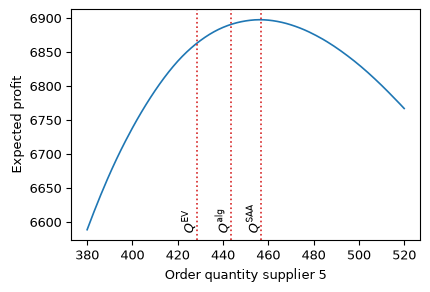

In [14]:
# mean profit on the comparison sample for Q = supplier 5 only
grid = np.arange(380, 521)
e5 = np.eye(10)[4]
curve = np.array([profit(q * e5, R_cmp, D_cmp, SP_cmp, inst).mean() for q in grid])
markers = {"EV": Q_EV, "alg": Q_alg, "SAA": Q_SAA}

for name, Q in markers.items():
    print(f"Q_{name}: active {active(Q)}, Q5 = {Q[4]:.2f}, profit = {profit(Q, R_cmp, D_cmp, SP_cmp, inst).mean():.2f}")
print(f"grid maximum: Q5 = {grid[curve.argmax()]}, profit = {curve.max():.2f}")
# profit on the grid around the three markers
near = pd.DataFrame([{"marker": name, "Q5": q, "profit": curve[q - grid[0]]}
                     for name, Q in markers.items() for q in range(round(Q[4]) - 3, round(Q[4]) + 4)])
print(near.round(2).to_string(index=False))

fig, ax = plt.subplots(figsize=(4.5, 3))
ax.plot(grid, curve, color="tab:blue")
for name, Q in markers.items():
    ax.axvline(Q[4], color="tab:red", linestyle=":")
    ax.text(Q[4], 0.03, rf"$Q^{{\mathrm{{{name}}}}}$", transform=ax.get_xaxis_transform(),
            rotation=90, ha="right", va="bottom")
ax.set_xlabel("Order quantity supplier 5")
ax.set_ylabel("Expected profit")
fig.savefig("results/fig_profit_curve.pdf", bbox_inches="tight")
plt.show()

 H    n  share  d_mean    d_lo    d_hi
 0 6146  0.615 -41.359 -45.351 -37.366
 1 3209  0.321  69.614  61.308  77.919
 2  617  0.062 151.905 132.503 171.306
 3   28  0.003 255.942 151.242 360.642


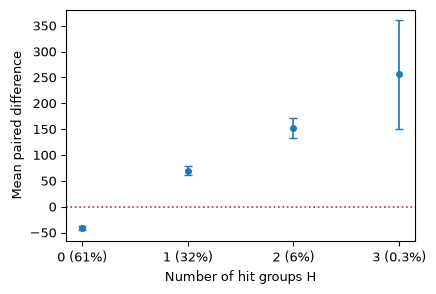

In [15]:
# paired difference Q_SAA - Q_alg on the comparison sample
d = Pi_SAA - Pi_alg
rows = []
for h in range(4):
    # mean and 95% CI per number of hit groups
    d_h = d[H_cmp == h]
    half = 1.96 * d_h.std(ddof=1) / np.sqrt(len(d_h))
    rows.append({"H": h, "n": len(d_h), "share": len(d_h) / N_COMPARE, "d_mean": d_h.mean(),
                 "d_lo": d_h.mean() - half, "d_hi": d_h.mean() + half})
by_H = pd.DataFrame(rows)
print(by_H.round(3).to_string(index=False))

fig, ax = plt.subplots(figsize=(4.5, 3))
ax.errorbar(by_H["H"], by_H["d_mean"], yerr=by_H["d_hi"] - by_H["d_mean"], fmt="o",
            color="tab:blue", markersize=4, capsize=3)
ax.axhline(0, color="tab:red", linestyle=":")
ax.set_xticks(by_H["H"], [f"{h} ({s:.0%})" if s >= 0.01 else f"{h} ({s:.1%})"
                          for h, s in zip(by_H["H"], by_H["share"])])
ax.set_xlabel("Number of hit groups H")
ax.set_ylabel("Mean paired difference")
fig.savefig("results/fig_diff_by_H.pdf", bbox_inches="tight")
plt.show()

## Export

In [16]:
candidates.round(2).to_csv("results/4_3_saa_candidates.csv", index=False)
saa.round(3).to_csv("results/4_3_saa_summary.csv", index=False)
comparison.round(2).to_csv("results/4_4_compare_alg.csv", index=False)
vss.round(2).to_csv("results/4_5_vss.csv", index=False)
evpi.round(2).assign(P_e=evpi["P_e"].round(6)).to_csv("results/4_6_evpi_groups.csv", index=False)
evpi_summary.round(2).to_csv("results/4_6_evpi_summary.csv", index=False)